# Sentiment-Based Sorting - LFS v7 (v2 model process + negation and slang handling)

Naive Bayes, Decision Tree, and a Naive Bayes -> Decision Tree hybrid.
Metrics: accuracy, F1-score, recall.

**Dataset:** `LFS v6 DATA.csv` (in the project root, one folder up) - 9,023 labeled texts in three datasets:
EduRABSA (6,489 rows), ISU Cauayan (1,901 rows, library-domain entries) and Kaggle (633 rows).
Columns: `text`, `sentiment`, `language` (english/tagalog/taglish), `source`, `category` and `dataset`.

**What is new in v7: the text cleaning.** The v2 process is unchanged (one 80/20 split stratified by sentiment, plain
Multinomial Naive Bayes with alpha 0.3, Decision Tree with balanced classes and leaf 2, Hybrid with threshold 0.9,
bag of unigrams and bigrams). Only `preprocess()` changed, and it now lives in `feedback/ml.py` so the notebook and the
app use the same code. It adds two steps to the old lowercase + letters-only cleaning:
1. **Slang / spelling normalization** - `u`->`you`, `pls`->`please`, `di`->`hindi`, `ung`->`yung`, `wi-fi`->`wifi` and similar.
2. **Negation handling** - contractions are expanded (`don't` -> `do not`), and the 3 words after a negator
   (`not`, `no`, `never`, `hindi`, `walang`, `wala`, `ayaw`, `huwag`, ...) inside the same clause get a `neg` token in front,
   so "not good" and "good" become different features.

These two were chosen from about 45 preprocessing variants (stopword removal, stemming, lemmatization, TF-IDF, other
tokenization and normalization choices were tried and did not help or hurt). Section 8b compares the v7 cleaning with the old cleaning.

Section 13 evaluates on the library-facilities rows specifically, since that is the deployment target.

## 1. Setup and load both datasets


In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix
import joblib

RANDOM_STATE = 42

df = pd.read_csv('../LFS v6 DATA.csv', encoding='utf-8-sig')

print('Shape:', df.shape)
print()
print(df['dataset'].value_counts())
print()
print(df['source'].value_counts())
print()
print(df['category'].value_counts())
print()
print(df['sentiment'].value_counts())
print()
print(pd.crosstab(df['language'], df['sentiment'], margins=True))
df.head()


Shape: (9023, 6)

dataset
EduRABSA       6489
ISU Cauayan    1901
Kaggle          633
Name: count, dtype: int64

source
edurabsa                        6489
local_taglish_aug                748
local                            633
local_library                    559
handwritten_train                300
quick_aspect_chips               167
handwritten_holdout               92
project_samples                   26
db_submissions_model_labeled       5
unit_test_fixtures                 4
Name: count, dtype: int64

category
edurabsa                 6489
library_facilities       1829
teaching                  123
coursecontent             112
examination               102
labwork                   100
extracurricular            96
Library Staff              23
Facilities                 22
Internet/Wi-Fi             22
Computer Services          22
Borrowing & Returning      21
Online Resources           21
Other                      21
Study Areas                20
Name: count, dtype: int6

,text,sentiment,language,source,category,dataset
0,He is not helpful at all and makes fun of stud...,negative,english,edurabsa,edurabsa,EduRABSA
1,"This course was amazing. For the first time, t...",neutral,english,edurabsa,edurabsa,EduRABSA
2,Exams were very easy and he allowed us to do e...,neutral,english,edurabsa,edurabsa,EduRABSA
3,The lecturers from Exeter have helped me throu...,positive,english,edurabsa,edurabsa,EduRABSA
4,"Extremely boring and lectures were useless, bu...",neutral,english,edurabsa,edurabsa,EduRABSA


## 2. Clean the text


In [2]:
# preprocess() is defined once, in the app (feedback/ml.py), so training and live use are identical.
import sys
sys.path.insert(0, '..')
from feedback.ml import preprocess

for t in ["Hindi maganda ang wifi, pls fix!", "The staff isn't helpful at all", "Wi-Fi is not good but the books are great"]:
    print(f'{t!r:50} -> {preprocess(t)!r}')
print()

df = df.drop_duplicates(subset='text').reset_index(drop=True)
df['clean'] = df['text'].apply(preprocess)
df = df[df['clean'].str.len() > 0].reset_index(drop=True)
print('Rows after cleaning:', len(df))
print(df['source'].value_counts())

'Hindi maganda ang wifi, pls fix!'                 -> 'hindi neg maganda neg ang neg wifi please fix'
"The staff isn't helpful at all"                   -> 'the staff is not neg helpful neg at neg all'
'Wi-Fi is not good but the books are great'        -> 'wifi is not neg good neg but neg the books are great'

Rows after cleaning: 9023
source
edurabsa                        6489
local_taglish_aug                748
local                            633
local_library                    559
handwritten_train                300
quick_aspect_chips               167
handwritten_holdout               92
project_samples                   26
db_submissions_model_labeled       5
unit_test_fixtures                 4
Name: count, dtype: int64


## 3. Split into train and test

80/20, stratified by sentiment across the merged dataset. Stratifying by
sentiment alone (not by source) means the split may not preserve the exact
EduRABSA-to-local ratio in each class, but it guarantees all three
sentiment classes appear in both sets, which matters more given how small
the local negative and neutral classes are.


In [3]:
train, test = train_test_split(
    df, test_size=0.20, stratify=df['sentiment'], random_state=RANDOM_STATE)

X_train, y_train = train['clean'], train['sentiment']
X_test,  y_test  = test['clean'],  test['sentiment']

vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=2)
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)

print('Train size:', Xtr.shape[0], '  Test size:', Xte.shape[0])
print('Test class counts:', y_test.value_counts().to_dict())
print('Test rows by dataset:', test['dataset'].value_counts().to_dict())
print('Test rows by language:', test['language'].value_counts().to_dict())
print('Library-facilities rows in test:', (test['category'] == 'library_facilities').sum())


Train size: 7218   Test size: 1805
Test class counts: {'neutral': 826, 'positive': 635, 'negative': 344}
Test rows by dataset: {'EduRABSA': 1292, 'ISU Cauayan': 401, 'Kaggle': 112}
Test rows by language: {'english': 1505, 'tagalog': 156, 'taglish': 144}
Library-facilities rows in test: 385


## 4. Naive Bayes


In [4]:
nb = MultinomialNB(alpha=0.3)
nb.fit(Xtr, y_train)
nb_pred = nb.predict(Xte)

print('Accuracy :', round(accuracy_score(y_test, nb_pred), 4))
print('F1-score :', round(f1_score(y_test, nb_pred, average='macro'), 4))
print('Recall   :', round(recall_score(y_test, nb_pred, average='macro'), 4))
print()
print(classification_report(y_test, nb_pred, digits=3))


Accuracy : 0.7618
F1-score : 0.75
Recall   : 0.7341

              precision    recall  f1-score   support

    negative      0.781     0.642     0.705       344
     neutral      0.713     0.856     0.778       826
    positive      0.842     0.704     0.767       635

    accuracy                          0.762      1805
   macro avg      0.779     0.734     0.750      1805
weighted avg      0.771     0.762     0.760      1805



## 5. Decision Tree


In [5]:
dt = DecisionTreeClassifier(class_weight='balanced', min_samples_leaf=2, random_state=RANDOM_STATE)
dt.fit(Xtr, y_train)
dt_pred = dt.predict(Xte)

print('Accuracy :', round(accuracy_score(y_test, dt_pred), 4))
print('F1-score :', round(f1_score(y_test, dt_pred, average='macro'), 4))
print('Recall   :', round(recall_score(y_test, dt_pred, average='macro'), 4))
print()
print(classification_report(y_test, dt_pred, digits=3))


Accuracy : 0.6864
F1-score : 0.6794
Recall   : 0.691

              precision    recall  f1-score   support

    negative      0.596     0.703     0.645       344
     neutral      0.749     0.667     0.706       826
    positive      0.673     0.702     0.687       635

    accuracy                          0.686      1805
   macro avg      0.672     0.691     0.679      1805
weighted avg      0.693     0.686     0.688      1805



## 6. Hybrid (Naive Bayes -> Decision Tree)

Naive Bayes classifies every review. Where its confidence is below the
threshold, the Decision Tree decides instead.


In [6]:
class Hybrid(BaseEstimator, ClassifierMixin):
    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y):
        self.nb_ = MultinomialNB(alpha=0.3).fit(X, y)
        self.dt_ = DecisionTreeClassifier(class_weight='balanced', min_samples_leaf=2,
                                          random_state=RANDOM_STATE).fit(X, y)
        return self

    def predict(self, X):
        proba = self.nb_.predict_proba(X)
        pred = self.nb_.predict(X).copy()
        low_confidence = proba.max(axis=1) < self.threshold
        if low_confidence.any():
            pred[low_confidence] = self.dt_.predict(X[low_confidence])
        return pred

hybrid = Hybrid(threshold=0.9)
hybrid.fit(Xtr, y_train)
hybrid_pred = hybrid.predict(Xte)

print('Accuracy :', round(accuracy_score(y_test, hybrid_pred), 4))
print('F1-score :', round(f1_score(y_test, hybrid_pred, average='macro'), 4))
print('Recall   :', round(recall_score(y_test, hybrid_pred, average='macro'), 4))
print()
print(classification_report(y_test, hybrid_pred, digits=3))


Accuracy : 0.7695
F1-score : 0.7574
Recall   : 0.7512

              precision    recall  f1-score   support

    negative      0.727     0.698     0.712       344
     neutral      0.750     0.843     0.794       826
    positive      0.828     0.713     0.766       635

    accuracy                          0.770      1805
   macro avg      0.768     0.751     0.757      1805
weighted avg      0.773     0.770     0.769      1805



## 7. Compare all three


In [7]:
results = pd.DataFrame({
    'Model': ['Naive Bayes', 'Decision Tree', 'Hybrid'],
    'Accuracy': [accuracy_score(y_test, nb_pred),
                accuracy_score(y_test, dt_pred),
                accuracy_score(y_test, hybrid_pred)],
    'F1-score': [f1_score(y_test, nb_pred, average='macro'),
                f1_score(y_test, dt_pred, average='macro'),
                f1_score(y_test, hybrid_pred, average='macro')],
    'Recall':   [recall_score(y_test, nb_pred, average='macro'),
                recall_score(y_test, dt_pred, average='macro'),
                recall_score(y_test, hybrid_pred, average='macro')],
}).set_index('Model').round(4)

results


,Accuracy,F1-score,Recall
Model,,,
Naive Bayes,0.7618,0.7500,0.7341
Decision Tree,0.6864,0.6794,0.6910
Hybrid,0.7695,0.7574,0.7512


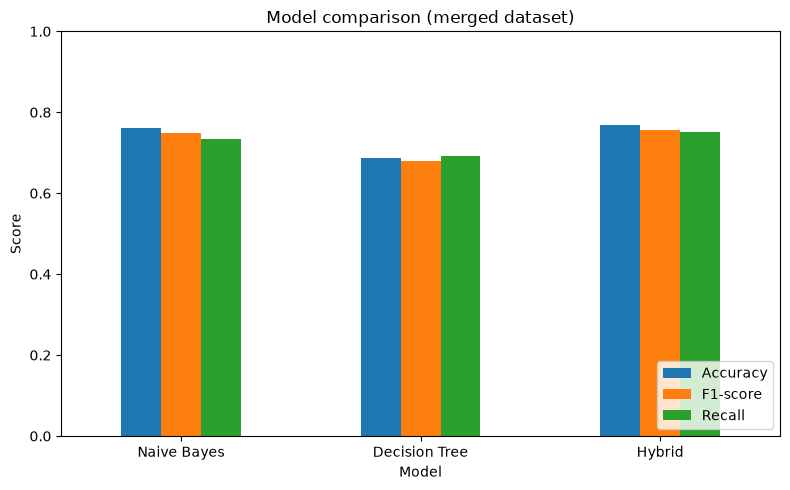

In [8]:
results.plot(kind='bar', figsize=(8, 5), rot=0)
plt.title('Model comparison (merged dataset)')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 8. Effect of text preprocessing (Objective a)

Objective (a) asks not just to apply preprocessing, but to determine its
**effect**. This section trains the same three models on the raw,
uncleaned text and compares that against the cleaned pipeline already
used above — same train/test rows, same model settings, only the text
input differs.


In [9]:
# Same train/test rows, but the vectorizer is fit on the ORIGINAL text
# (before lowercasing, punctuation stripping, etc.) instead of 'clean'.
vectorizer_raw = CountVectorizer(ngram_range=(1, 2), min_df=2)
Xtr_raw = vectorizer_raw.fit_transform(train['text'])
Xte_raw = vectorizer_raw.transform(test['text'])

nb_raw = MultinomialNB(alpha=0.3).fit(Xtr_raw, y_train)
dt_raw = DecisionTreeClassifier(class_weight='balanced', min_samples_leaf=2,
                                random_state=RANDOM_STATE).fit(Xtr_raw, y_train)
hybrid_raw = Hybrid(threshold=0.9).fit(Xtr_raw, y_train)

nb_raw_pred = nb_raw.predict(Xte_raw)
dt_raw_pred = dt_raw.predict(Xte_raw)
hybrid_raw_pred = hybrid_raw.predict(Xte_raw)

preprocessing_effect = pd.DataFrame([
    {'Preprocessing': 'Raw (uncleaned)', 'Model': 'Naive Bayes',
     'Accuracy': accuracy_score(y_test, nb_raw_pred),
     'F1-score': f1_score(y_test, nb_raw_pred, average='macro')},
    {'Preprocessing': 'Raw (uncleaned)', 'Model': 'Decision Tree',
     'Accuracy': accuracy_score(y_test, dt_raw_pred),
     'F1-score': f1_score(y_test, dt_raw_pred, average='macro')},
    {'Preprocessing': 'Raw (uncleaned)', 'Model': 'Hybrid',
     'Accuracy': accuracy_score(y_test, hybrid_raw_pred),
     'F1-score': f1_score(y_test, hybrid_raw_pred, average='macro')},
    {'Preprocessing': 'Cleaned', 'Model': 'Naive Bayes',
     'Accuracy': accuracy_score(y_test, nb_pred),
     'F1-score': f1_score(y_test, nb_pred, average='macro')},
    {'Preprocessing': 'Cleaned', 'Model': 'Decision Tree',
     'Accuracy': accuracy_score(y_test, dt_pred),
     'F1-score': f1_score(y_test, dt_pred, average='macro')},
    {'Preprocessing': 'Cleaned', 'Model': 'Hybrid',
     'Accuracy': accuracy_score(y_test, hybrid_pred),
     'F1-score': f1_score(y_test, hybrid_pred, average='macro')},
]).round(4)

preprocessing_effect


,Preprocessing,Model,Accuracy,F1-score
0,Raw (uncleaned),Naive Bayes,0.7490,0.7350
1,Raw (uncleaned),Decision Tree,0.6881,0.6763
2,Raw (uncleaned),Hybrid,0.7579,0.7425
3,Cleaned,Naive Bayes,0.7618,0.7500
4,Cleaned,Decision Tree,0.6864,0.6794
5,Cleaned,Hybrid,0.7695,0.7574


In [10]:
# The effect, isolated: cleaned minus raw, per model.
delta = preprocessing_effect.pivot(index='Model', columns='Preprocessing', values='Accuracy')
delta['Accuracy change'] = delta['Cleaned'] - delta['Raw (uncleaned)']
print(delta.round(4))
print()
print('Positive = cleaning helped this model. Negative = cleaning hurt it.')
print('Report this table directly for Objective (a) - it measures the effect')
print('instead of only asserting that preprocessing was applied.')


Preprocessing  Cleaned  Raw (uncleaned)  Accuracy change
Model                                                   
Decision Tree   0.6864           0.6881          -0.0017
Hybrid          0.7695           0.7579           0.0116
Naive Bayes     0.7618           0.7490           0.0128

Positive = cleaning helped this model. Negative = cleaning hurt it.
Report this table directly for Objective (a) - it measures the effect
instead of only asserting that preprocessing was applied.


## 8b. Effect of the v7 cleaning against the old cleaning (Objective a)

The comparison above is raw text against cleaned text. This one compares the **old cleaning** (lowercase and letters only)
with the **v7 cleaning** (adds slang normalization and negation handling): same train/test rows, same model settings, only the
text input differs.


In [11]:
import re

def old_preprocess(text):
    return ' '.join(re.sub(r'[^a-zA-Z\s]', ' ', str(text).lower()).split())

old_train = train['text'].apply(old_preprocess)
old_test = test['text'].apply(old_preprocess)
vec_old = CountVectorizer(ngram_range=(1, 2), min_df=2)
Xtr_old = vec_old.fit_transform(old_train)
Xte_old = vec_old.transform(old_test)

old_models = {'Naive Bayes': MultinomialNB(alpha=0.3).fit(Xtr_old, y_train),
              'Decision Tree': DecisionTreeClassifier(class_weight='balanced', min_samples_leaf=2, random_state=RANDOM_STATE).fit(Xtr_old, y_train),
              'Hybrid': Hybrid(threshold=0.9).fit(Xtr_old, y_train)}
new_preds = {'Naive Bayes': nb_pred, 'Decision Tree': dt_pred, 'Hybrid': hybrid_pred}

rows = []
for name, model in old_models.items():
    p_old = model.predict(Xte_old)
    p_new = new_preds[name]
    rows.append({'Model': name,
                 'Old accuracy': accuracy_score(y_test, p_old), 'v7 accuracy': accuracy_score(y_test, p_new),
                 'Accuracy change': accuracy_score(y_test, p_new) - accuracy_score(y_test, p_old),
                 'Old F1': f1_score(y_test, p_old, average='macro'), 'v7 F1': f1_score(y_test, p_new, average='macro'),
                 'Old negative recall': recall_score(y_test, p_old, labels=['negative'], average=None)[0],
                 'v7 negative recall': recall_score(y_test, p_new, labels=['negative'], average=None)[0]})
cleaning_effect = pd.DataFrame(rows).set_index('Model').round(4)
print('Features: old', Xtr_old.shape[1], ' v7', Xtr.shape[1])
cleaning_effect

Features: old 25846  v7 25915


,Old accuracy,v7 accuracy,Accuracy change,Old F1,v7 F1,Old negative recall,v7 negative recall
Model,,,,,,,
Naive Bayes,0.7507,0.7618,0.0111,0.7366,0.7500,0.6105,0.6424
Decision Tree,0.6859,0.6864,0.0006,0.6747,0.6794,0.6948,0.7035
Hybrid,0.7562,0.7695,0.0133,0.7404,0.7574,0.6395,0.6977


## 9. Save the model for Django

Save the trained hybrid model and the vectorizer **together**, as two
separate `.pkl` files. A common integration bug is saving only the model
and re-fitting the vectorizer at inference time — that builds a different
feature space and produces nonsense predictions. Django's view loads both
with `joblib.load()` and applies them in the same order every time.

The files are written next to this notebook (the `v7 model` folder). They are **not** deployed: to use them in the app, copy both files to the project root.


In [12]:
joblib.dump(hybrid, 'sentiment_model.pkl')
joblib.dump(vectorizer, 'vectorizer.pkl')
print('Saved: sentiment_model.pkl, vectorizer.pkl')

# Sanity check - this is exactly what your Django view will do:
loaded_model = joblib.load('sentiment_model.pkl')
loaded_vec   = joblib.load('vectorizer.pkl')

for t in ['the aircon on the 2nd floor is too warm', 'the librarian helped me find the book right away']:
    cleaned = preprocess(t)
    pred = loaded_model.predict(loaded_vec.transform([cleaned]))[0]
    print(f'{pred:9} <- {t}')


Saved: sentiment_model.pkl, vectorizer.pkl
negative  <- the aircon on the 2nd floor is too warm
positive  <- the librarian helped me find the book right away


## 10. Confusion matrices


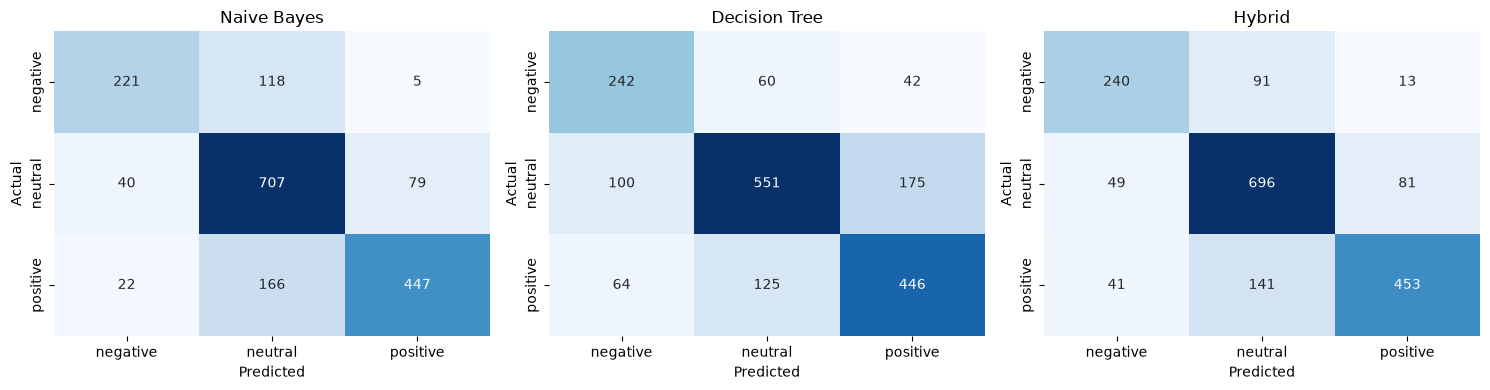

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ['negative', 'neutral', 'positive']
for ax, name, pred in zip(axes, ['Naive Bayes', 'Decision Tree', 'Hybrid'],
                          [nb_pred, dt_pred, hybrid_pred]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


## 11. Cross-validation on the merged training set

A single 80/20 split leaves a modest test set. 5-fold cross-validation on the
training portion gives a mean and standard deviation, so you can say whether
a difference between models is real or just the luck of one split.


In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in [('Naive Bayes', MultinomialNB(alpha=0.3)),
                    ('Decision Tree', DecisionTreeClassifier(class_weight='balanced', min_samples_leaf=2, random_state=RANDOM_STATE)),
                    ('Hybrid', Hybrid(threshold=0.9))]:
    pipe = Pipeline([('v', CountVectorizer(ngram_range=(1,2), min_df=2)), ('c', model)])
    acc = cross_val_score(pipe, train['clean'], train['sentiment'], cv=cv, scoring='accuracy')
    f1m = cross_val_score(pipe, train['clean'], train['sentiment'], cv=cv, scoring='f1_macro')
    cv_rows.append({'Model': name,
                    'CV Accuracy': f'{acc.mean():.4f} +/- {acc.std():.4f}',
                    'CV Macro F1': f'{f1m.mean():.4f} +/- {f1m.std():.4f}'})
pd.DataFrame(cv_rows).set_index('Model')


,CV Accuracy,CV Macro F1
Model,,
Naive Bayes,0.7519 +/- 0.0068,0.7376 +/- 0.0124
Decision Tree,0.6973 +/- 0.0119,0.6860 +/- 0.0112
Hybrid,0.7681 +/- 0.0104,0.7536 +/- 0.0131


## 12. Sort feedback by sentiment priority

Negative first, then neutral, then positive.


In [15]:
SENTIMENT_PRIORITY = {'negative': 0, 'neutral': 1, 'positive': 2}

def sort_feedback(texts):
    cleaned = [preprocess(t) for t in texts]
    V = vectorizer.transform(cleaned)
    labels_ = hybrid.predict(V)
    out = pd.DataFrame({'feedback': texts, 'sentiment': labels_})
    out['priority'] = out['sentiment'].map(SENTIMENT_PRIORITY)
    return out.sort_values('priority').drop(columns='priority').reset_index(drop=True)

sample = [
    "the wifi keeps dropping on the 2nd floor quiet study area",
    "the librarian at the circulation desk was very helpful",
    "the collection has enough books but the database access is limited",
    "i never got a reply about the reserved book i requested",
    "borrowing and returning was fast and easy, thank you",
]
sort_feedback(sample)


,feedback,sentiment
0,the wifi keeps dropping on the 2nd floor quiet...,negative
1,i never got a reply about the reserved book i ...,negative
2,the collection has enough books but the databa...,neutral
3,the librarian at the circulation desk was very...,positive
4,"borrowing and returning was fast and easy, tha...",positive


## 13. Library-facilities performance

This is the actual deployment target. It isolates the library-facilities
rows in the test set and reports how each model does on them specifically,
separate from the merged average above.


In [16]:
lib_mask = test['category'] == 'library_facilities'
lib_test = test[lib_mask]
lib_Xte = vectorizer.transform(lib_test['clean'])
lib_ytrue = lib_test['sentiment']

print('Library-facilities rows in test set:', len(lib_test))
print(lib_ytrue.value_counts().to_dict())
print()

for name, model in [('Naive Bayes', nb), ('Decision Tree', dt), ('Hybrid', hybrid)]:
    pred = model.predict(lib_Xte)
    acc = accuracy_score(lib_ytrue, pred)
    f1 = f1_score(lib_ytrue, pred, average='macro', zero_division=0)
    print(f'{name:15} accuracy={acc:.4f}  macro F1={f1:.4f}')

print()
print('--- Hybrid detail on library-facilities rows only ---')
lib_pred = hybrid.predict(lib_Xte)
print(classification_report(lib_ytrue, lib_pred, digits=3, zero_division=0))


Library-facilities rows in test set: 385
{'negative': 155, 'positive': 115, 'neutral': 115}

Naive Bayes     accuracy=0.8727  macro F1=0.8683
Decision Tree   accuracy=0.8649  macro F1=0.8626
Hybrid          accuracy=0.8727  macro F1=0.8694

--- Hybrid detail on library-facilities rows only ---
              precision    recall  f1-score   support

    negative      0.813     0.981     0.889       155
     neutral      0.967     0.765     0.854       115
    positive      0.897     0.835     0.865       115

    accuracy                          0.873       385
   macro avg      0.892     0.860     0.869       385
weighted avg      0.884     0.873     0.871       385



## 14. Evaluating the sorting mechanism (Objective c)

Section 12 shows the sorting mechanism *works* — it arranges classified
text by priority. This section checks whether the arrangement is
*correct*, by comparing the priority order the system produces (from
predicted sentiment) against the priority order the true labels would
produce, on the full test set.

Two measures:
- **Spearman rank correlation** between true priority and predicted
  priority across all test rows. Closer to 1.0 means the predicted
  ordering tracks the true ordering closely.
- **Pairwise concordance**: for every pair of test entries where the true
  labels say one is strictly more urgent (more negative) than the other,
  what fraction of the time does the predicted arrangement place it no
  later than the other?

This is a computational check of ranking correctness, not a substitute
for the usability evaluation Objective (c) and Objective (d) also call
for - it does not tell you whether library staff find the arrangement
useful, only whether it is arithmetically consistent with the ground
truth labels.


In [17]:
from scipy.stats import spearmanr

true_priority = y_test.map(SENTIMENT_PRIORITY).to_numpy()
pred_priority = pd.Series(hybrid_pred, index=y_test.index).map(SENTIMENT_PRIORITY).to_numpy()

rho, pval = spearmanr(true_priority, pred_priority)
print(f'Spearman rank correlation: {rho:.4f}  (p={pval:.4g})')

# Pairwise concordance over all test rows.
tp = true_priority.reshape(-1, 1)
pp = pred_priority.reshape(-1, 1)
true_more_urgent = tp < tp.T          # row is truly more urgent than col
pred_not_later   = pp <= pp.T         # predicted arrangement does not rank row after col

concordant_pairs = (true_more_urgent & pred_not_later).sum()
total_urgent_pairs = true_more_urgent.sum()
concordance = concordant_pairs / total_urgent_pairs

print(f'Pairwise sorting concordance: {concordance:.4f}')
print(f'  ({concordant_pairs:,} of {total_urgent_pairs:,} urgent-priority pairs correctly ordered)')


Spearman rank correlation: 0.6773  (p=1.336e-242)
Pairwise sorting concordance: 0.9382
  (963,575 of 1,027,094 urgent-priority pairs correctly ordered)


## 15. Results by dataset and by language 

The test split is a random 20% of all 9,023 rows, so it mixes the three datasets. These tables show how the three
models do on each part of it. Counts are small for some groups; read accuracy on a few dozen rows as indicative only.


In [18]:
def breakdown(col):
    rows = {}
    for grp, frame in test.groupby(col):
        k = frame.index
        row = {'n': len(frame)}
        for name, pred in [('Naive Bayes', nb_pred), ('Decision Tree', dt_pred), ('Hybrid', hybrid_pred)]:
            p = pd.Series(pred, index=y_test.index).loc[k]
            row[f'{name} acc'] = accuracy_score(frame['sentiment'], p)
            row[f'{name} F1'] = f1_score(frame['sentiment'], p, average='macro', zero_division=0)
        rows[grp] = row
    return pd.DataFrame(rows).T.round(3)

print('By dataset:')
print(breakdown('dataset').to_string())
print()
print('By language:')
print(breakdown('language').to_string())

By dataset:
                  n  Naive Bayes acc  Naive Bayes F1  Decision Tree acc  Decision Tree F1  Hybrid acc  Hybrid F1
EduRABSA     1292.0            0.735           0.658              0.632             0.588       0.743      0.677
ISU Cauayan   401.0            0.860           0.856              0.870             0.868       0.873      0.870
Kaggle        112.0            0.714           0.677              0.652             0.602       0.705      0.657

By language:
              n  Naive Bayes acc  Naive Bayes F1  Decision Tree acc  Decision Tree F1  Hybrid acc  Hybrid F1
english  1505.0            0.738           0.692              0.643             0.614       0.746      0.705
tagalog   156.0            0.872           0.869              0.878             0.879       0.891      0.889
taglish   144.0            0.889           0.881              0.931             0.925       0.889      0.883
